<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/Lab%20Exp/CO2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loan data: (100, 2) | approved: 48 | rejected: 52

Epoch | w1      w2      bias    | misclassified
    1 |   0.280   0.105  -0.200 | 20
    2 |   0.310   0.215  -0.300 | 11
    3 |   0.334   0.233  -0.300 | 2
    4 |   0.334   0.233  -0.300 | 0

Converged in 4 epochs, training accuracy = 100.0%


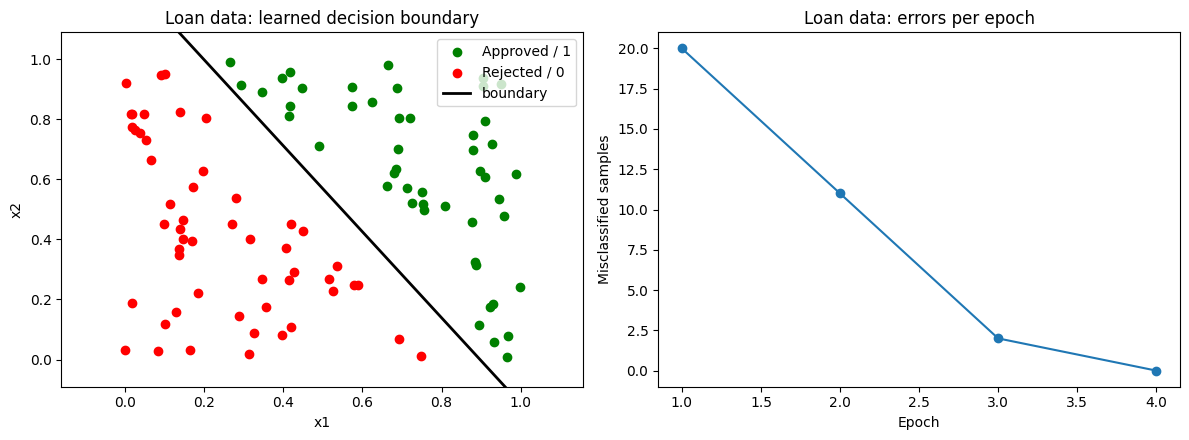


XOR: errors in last 5 epochs = [4, 4, 4, 4, 5]  (never reaches 0)
XOR accuracy = 75.0%


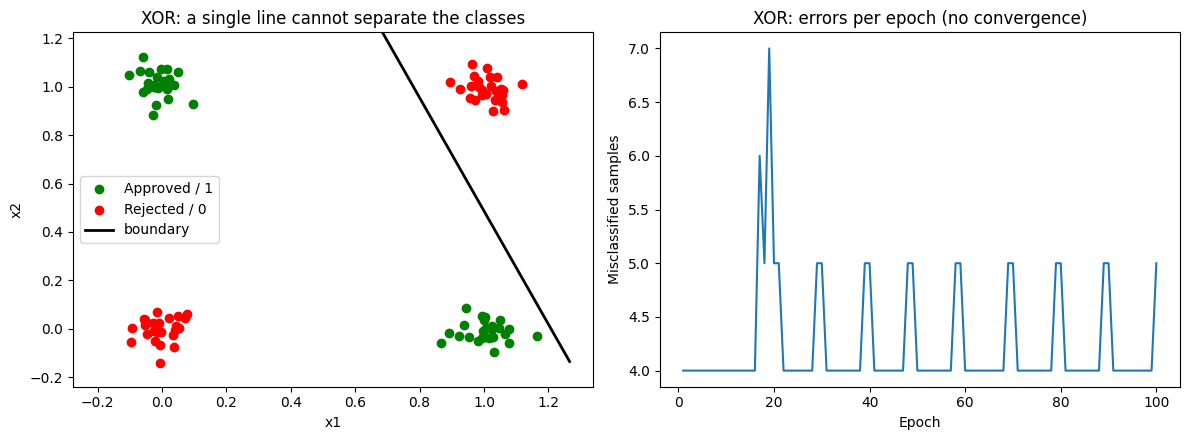


   z   |  step | sigmoid |  ReLU
  -3.0 |     0 |   0.047 |  0.00
  -1.0 |     0 |   0.269 |  0.00
  -0.5 |     0 |   0.378 |  0.00
   0.0 |     1 |   0.500 |  0.00
   0.5 |     1 |   0.622 |  0.50
   1.0 |     1 |   0.731 |  1.00
   3.0 |     1 |   0.953 |  3.00


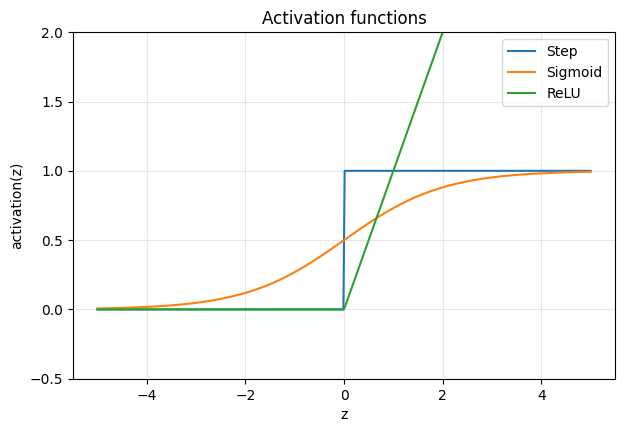

In [ ]:
"""Experiment 7: Perceptron and Forward Propagation"""
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

# ---------------- Data 1: loan applications (credit score, income-to-debt ratio) ----------------
credit = np.random.uniform(300, 900, 400)
ratio = np.random.uniform(0.5, 5, 400)
score = 0.6 * (credit - 300) / 600 + 0.4 * (ratio - 0.5) / 4.5
keep = np.abs(score - 0.5) > 0.04                  # keep a clear margin so the data is separable
credit, ratio, score = credit[keep][:100], ratio[keep][:100], score[keep][:100]
y_loan = (score > 0.5).astype(int)                 # 1 = Approved, 0 = Rejected
X_loan = np.column_stack([(credit - 300) / 600, (ratio - 0.5) / 4.5])   # scale to 0-1
print("Loan data:", X_loan.shape, "| approved:", y_loan.sum(), "| rejected:", (1 - y_loan).sum())

# ---------------- Data 2: XOR pattern (100 noisy points) ----------------
base = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
base_y = np.array([0, 1, 1, 0])
X_xor = np.repeat(base, 25, axis=0) + np.random.normal(0, 0.05, (100, 2))
y_xor = np.repeat(base_y, 25)

# ---------------- Task 1: perceptron (weighted sum + bias + step) ----------------
def step(z):
    return (z >= 0).astype(int)

class Perceptron:
    def __init__(self, n_inputs, lr=0.1):
        self.w = np.zeros(n_inputs)
        self.b = 0.0
        self.lr = lr

    def forward(self, X):                          # forward propagation
        z = X @ self.w + self.b                    # weighted sum + bias
        return step(z)                             # step activation

    def fit(self, X, y, epochs=50):
        self.history, self.errors = [], []
        for ep in range(1, epochs + 1):
            errs = 0
            for xi, ti in zip(X, y):
                pred = int(xi @ self.w + self.b >= 0)
                delta = self.lr * (ti - pred)      # perceptron learning rule
                if delta != 0:
                    self.w = self.w + delta * xi
                    self.b = self.b + delta
                    errs += 1
            self.errors.append(errs)
            self.history.append((ep, self.w.copy(), self.b))
            if errs == 0:
                break

# ---------------- Task 2: train on loan data ----------------
p = Perceptron(2, lr=0.1)
p.fit(X_loan, y_loan, epochs=100)
print("\nEpoch | w1      w2      bias    | misclassified")
for (ep, w, b), e in zip(p.history, p.errors):
    print(f"{ep:5d} | {w[0]:7.3f} {w[1]:7.3f} {b:7.3f} | {e}")
acc = (p.forward(X_loan) == y_loan).mean()
print(f"\nConverged in {len(p.errors)} epochs, training accuracy = {acc*100:.1f}%")

# ---------------- Task 3: decision boundary ----------------
def plot_boundary(model, X, y, title, ax):
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="green", label="Approved / 1")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="red", label="Rejected / 0")
    xs = np.linspace(X[:, 0].min() - 0.1, X[:, 0].max() + 0.1, 100)
    if abs(model.w[1]) > 1e-9:
        ax.plot(xs, -(model.w[0] * xs + model.b) / model.w[1], "k-", lw=2, label="boundary")   # w1x1 + w2x2 + b = 0
    ax.set_ylim(X[:, 1].min() - 0.1, X[:, 1].max() + 0.1)
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title(title); ax.legend()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
plot_boundary(p, X_loan, y_loan, "Loan data: learned decision boundary", ax[0])
ax[1].plot(range(1, len(p.errors) + 1), p.errors, "o-")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Misclassified samples"); ax[1].set_title("Loan data: errors per epoch")
plt.tight_layout(); plt.show()

# ---------------- Task 4: XOR fails ----------------
px = Perceptron(2, lr=0.1)
px.fit(X_xor, y_xor, epochs=100)
print(f"\nXOR: errors in last 5 epochs = {px.errors[-5:]}  (never reaches 0)")
print(f"XOR accuracy = {(px.forward(X_xor) == y_xor).mean()*100:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
plot_boundary(px, X_xor, y_xor, "XOR: a single line cannot separate the classes", ax[0])
ax[1].plot(range(1, len(px.errors) + 1), px.errors)
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Misclassified samples"); ax[1].set_title("XOR: errors per epoch (no convergence)")
plt.tight_layout(); plt.show()

# ---------------- Task 5: step vs sigmoid vs ReLU ----------------
sigmoid = lambda z: 1 / (1 + np.exp(-z))
relu = lambda z: np.maximum(0, z)
z = np.array([-3, -1, -0.5, 0, 0.5, 1, 3])
print("\n   z   |  step | sigmoid |  ReLU")
for zi in z:
    print(f"{zi:6.1f} | {int(zi >= 0):5d} | {sigmoid(zi):7.3f} | {relu(zi):5.2f}")

zz = np.linspace(-5, 5, 400)
plt.figure(figsize=(7, 4.5))
plt.plot(zz, step(zz), label="Step"); plt.plot(zz, sigmoid(zz), label="Sigmoid"); plt.plot(zz, relu(zz), label="ReLU")
plt.ylim(-0.5, 2); plt.xlabel("z"); plt.ylabel("activation(z)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Activation functions"); plt.show()

[XOR-style loan data] gradient check W1[0,0]: analytic=0.00029659  numeric=0.00029659  diff=1.13e-11
[XOR-style loan data] gradient check W2[0,0]: analytic=-0.02589536  numeric=-0.02589536  diff=1.36e-10
[XOR-style loan data] final loss = 0.0396, accuracy = 100.0%

[Two-moons segmentation] gradient check W1[0,0]: analytic=-0.03827935  numeric=-0.03827935  diff=1.02e-10
[Two-moons segmentation] gradient check W2[0,0]: analytic=-0.10896026  numeric=-0.10896026  diff=3.61e-10
[Two-moons segmentation] final loss = 0.0658, accuracy = 98.0%



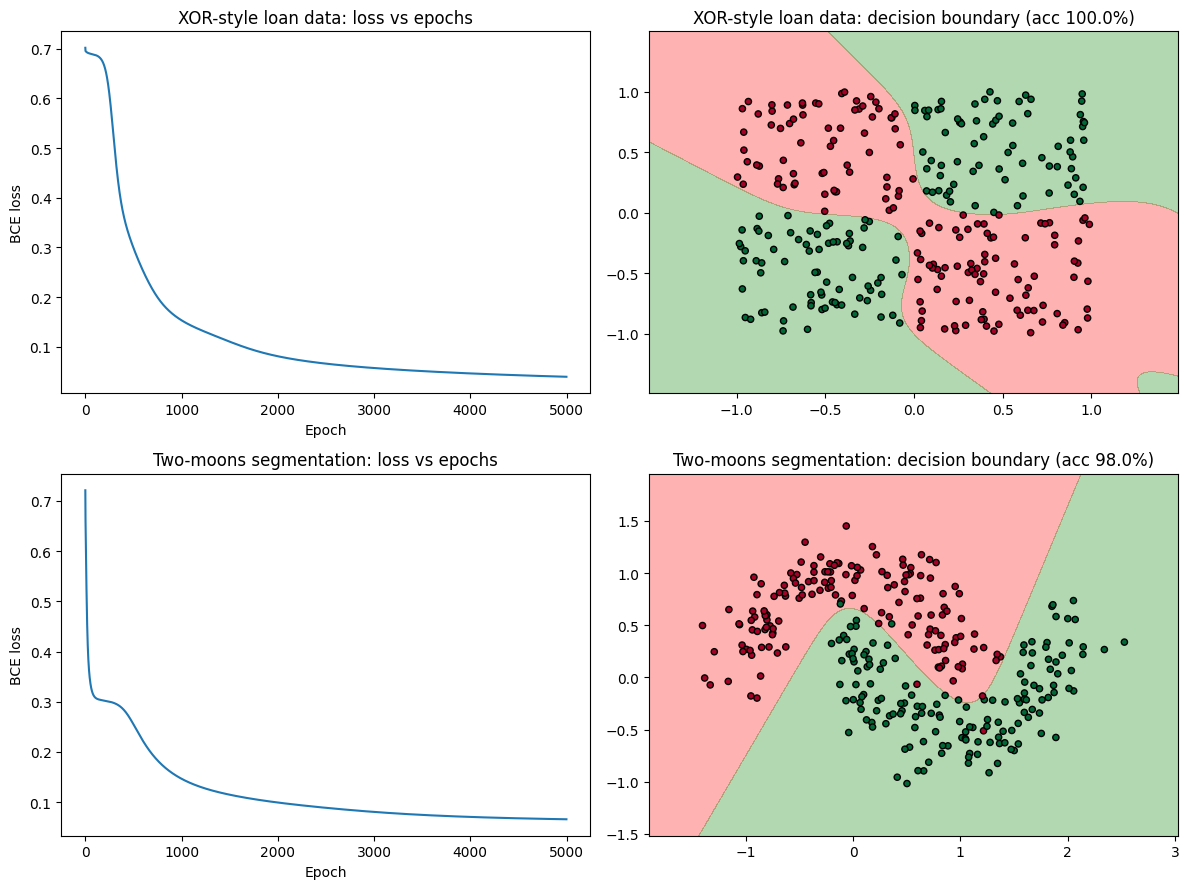

In [1]:
"""Experiment 8: Two-Layer Neural Network with Backpropagation (from scratch)"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

np.random.seed(0)

# ---------------- Datasets ----------------
# (a) XOR-style loan data: approved when credit score and income ratio are BOTH high or BOTH low
X_xor = np.random.uniform(-1, 1, (300, 2))
y_xor = ((X_xor[:, 0] * X_xor[:, 1]) > 0).astype(float).reshape(-1, 1)
# (b) two-moons customer segmentation
X_moon, y_moon = make_moons(300, noise=0.2, random_state=0)
y_moon = y_moon.reshape(-1, 1).astype(float)

# ---------------- Task 1: initialise weights ----------------
def init_params(n_in, n_hidden, n_out, seed=0):
    rng = np.random.RandomState(seed)
    return {"W1": rng.randn(n_in, n_hidden) * 0.5, "b1": np.zeros((1, n_hidden)),
            "W2": rng.randn(n_hidden, n_out) * 0.5, "b2": np.zeros((1, n_out))}

# ---------------- Task 2: forward pass ----------------
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def forward(X, p):
    z1 = X @ p["W1"] + p["b1"]
    a1 = sigmoid(z1)                      # hidden layer
    z2 = a1 @ p["W2"] + p["b2"]
    a2 = sigmoid(z2)                      # output layer
    return z1, a1, z2, a2

def bce_loss(y, a2):
    eps = 1e-9
    return -np.mean(y * np.log(a2 + eps) + (1 - y) * np.log(1 - a2 + eps))

# ---------------- Task 3: backward pass (chain rule) ----------------
# L = BCE(a2, y);  dL/dz2 = a2 - y  (BCE + sigmoid simplification)
# dL/dW2 = a1^T dz2 ; dL/da1 = dz2 W2^T ; dL/dz1 = da1 * a1(1-a1) ; dL/dW1 = X^T dz1
def backward(X, y, cache, p):
    z1, a1, z2, a2 = cache
    m = X.shape[0]
    dz2 = (a2 - y) / m
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    da1 = dz2 @ p["W2"].T
    dz1 = da1 * a1 * (1 - a1)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

# ---------------- Task 4: training with gradient descent ----------------
def train(X, y, n_hidden=8, lr=1.0, epochs=5000, seed=0):
    p = init_params(X.shape[1], n_hidden, 1, seed)
    losses = []
    for ep in range(epochs):
        cache = forward(X, p)
        losses.append(bce_loss(y, cache[3]))
        g = backward(X, y, cache, p)
        for k in p:
            p[k] -= lr * g[k]
    return p, losses

def plot_boundary(p, X, y, title, ax):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    zz = forward(np.c_[xx.ravel(), yy.ravel()], p)[3].reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[0, 0.5, 1], alpha=0.3, colors=["red", "green"])
    ax.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="RdYlGn", edgecolors="k", s=20)
    ax.set_title(title)

# ---------------- Task 5: gradient check ----------------
def gradient_check(X, y, p, key="W1", idx=(0, 0), eps=1e-5):
    cache = forward(X, p)
    analytic = backward(X, y, cache, p)[key][idx]
    p[key][idx] += eps; lp = bce_loss(y, forward(X, p)[3])
    p[key][idx] -= 2 * eps; lm = bce_loss(y, forward(X, p)[3])
    p[key][idx] += eps
    numeric = (lp - lm) / (2 * eps)
    return analytic, numeric

fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for row, (name, X, y) in enumerate([("XOR-style loan data", X_xor, y_xor), ("Two-moons segmentation", X_moon, y_moon)]):
    # check gradients on the untrained network first
    p0 = init_params(2, 8, 1)
    a, n = gradient_check(X, y, p0, "W1", (0, 0))
    print(f"[{name}] gradient check W1[0,0]: analytic={a:.8f}  numeric={n:.8f}  diff={abs(a-n):.2e}")
    a, n = gradient_check(X, y, p0, "W2", (0, 0))
    print(f"[{name}] gradient check W2[0,0]: analytic={a:.8f}  numeric={n:.8f}  diff={abs(a-n):.2e}")

    p, losses = train(X, y)
    acc = ((forward(X, p)[3] > 0.5) == y).mean()
    print(f"[{name}] final loss = {losses[-1]:.4f}, accuracy = {acc*100:.1f}%\n")
    ax[row, 0].plot(losses); ax[row, 0].set_title(f"{name}: loss vs epochs")
    ax[row, 0].set_xlabel("Epoch"); ax[row, 0].set_ylabel("BCE loss")
    plot_boundary(p, X, y, f"{name}: decision boundary (acc {acc*100:.1f}%)", ax[row, 1])
plt.tight_layout(); plt.show()

   tenure  monthly_charges        contract  complaints  data_usage_gb  Churn
0      52           114.30        One year           2            2.3      0
1      15            62.24  Month-to-month           2           28.1      0
2      72            57.73        One year           0           11.4      0
3      61           113.63        One year           0           15.1      0
4      21            87.51        One year           1           45.6      0

Churn rate: 0.293
Processed feature shape: (2400, 6)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

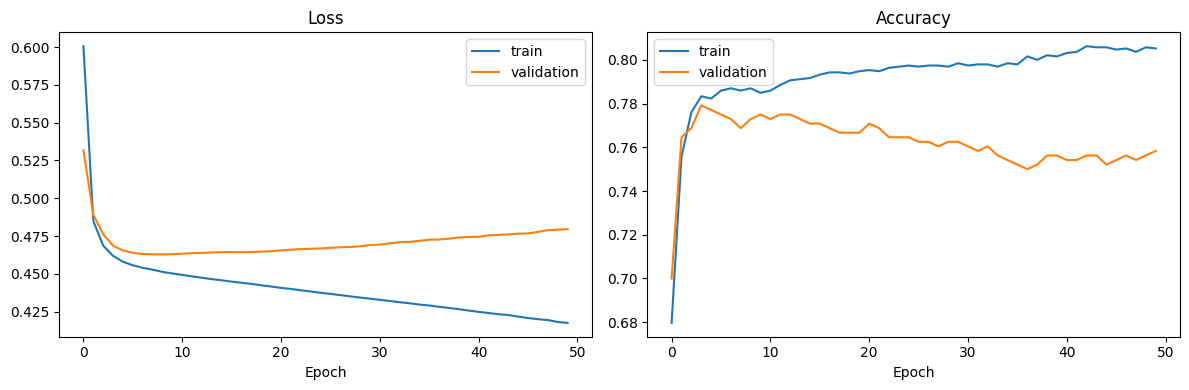

Accuracy : 0.7667
Precision: 0.6636
Recall   : 0.4148
F1-score : 0.5105
Confusion matrix:
 [[387  37]
 [103  73]]


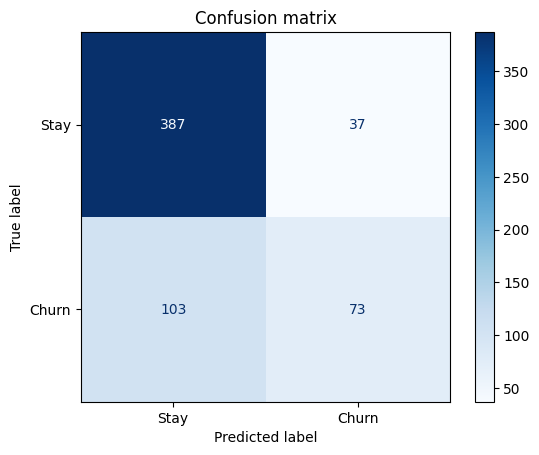


  Width  Params  Accuracy     F1
     8      97    0.7617 0.5153
    16     257    0.7483 0.4983
    32     769    0.7467 0.4899
    64    2561    0.7633 0.5035
   128    9217    0.7633 0.5069
   256   34817    0.7600 0.5068


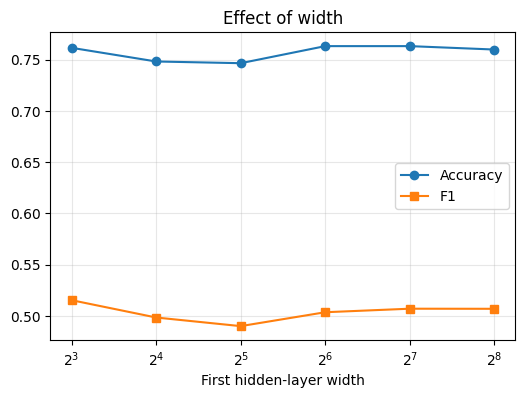

In [2]:
"""Experiment 9: Multilayer Perceptron Implementation (Customer Churn)"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

np.random.seed(42); tf.random.set_seed(42)

# ---------------- Synthetic telecom churn dataset ----------------
n = 3000
df = pd.DataFrame({
    "tenure": np.random.randint(1, 73, n),
    "monthly_charges": np.round(np.random.uniform(20, 120, n), 2),
    "contract": np.random.choice(["Month-to-month", "One year", "Two year"], n, p=[0.5, 0.3, 0.2]),
    "complaints": np.random.poisson(0.8, n),
    "data_usage_gb": np.round(np.random.uniform(1, 50, n), 1),
})
contract_effect = df["contract"].map({"Month-to-month": 1.0, "One year": -0.2, "Two year": -1.2})
logit = -0.3 - 0.05 * df["tenure"] + 0.025 * (df["monthly_charges"] - 65) + 0.5 * df["complaints"] + contract_effect
df["Churn"] = (np.random.rand(n) < 1 / (1 + np.exp(-logit))).astype(int)
print(df.head()); print("\nChurn rate:", round(df["Churn"].mean(), 3))

# ---------------- Task 1: pre-processing ----------------
X, y = df.drop(columns="Churn"), df["Churn"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
pre = ColumnTransformer([
    ("num", StandardScaler(), ["tenure", "monthly_charges", "complaints", "data_usage_gb"]),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), ["contract"])])
X_tr = pre.fit_transform(X_tr); X_te = pre.transform(X_te)       # fit on train only
print("Processed feature shape:", X_tr.shape)

# ---------------- Task 2: build MLP ----------------
def build_mlp(width=64, n_hidden=3):
    m = keras.Sequential([keras.layers.Input((X_tr.shape[1],))])
    for i in range(n_hidden):
        m.add(keras.layers.Dense(max(width // (2 ** i), 4), activation="relu"))
    m.add(keras.layers.Dense(1, activation="sigmoid"))
    # ---------------- Task 3: BCE + Adam ----------------
    m.compile(optimizer=keras.optimizers.Adam(0.001), loss="binary_crossentropy", metrics=["accuracy"])
    return m

model = build_mlp(64, 3)
model.summary()
hist = model.fit(X_tr, y_tr, validation_split=0.2, epochs=50, batch_size=32, verbose=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

# ---------------- Task 4: evaluation ----------------
y_pred = (model.predict(X_te, verbose=0).ravel() > 0.5).astype(int)
print(f"Accuracy : {accuracy_score(y_te, y_pred):.4f}")
print(f"Precision: {precision_score(y_te, y_pred):.4f}")
print(f"Recall   : {recall_score(y_te, y_pred):.4f}")
print(f"F1-score : {f1_score(y_te, y_pred):.4f}")
cm = confusion_matrix(y_te, y_pred)
print("Confusion matrix:\n", cm)
ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(cmap="Blues")
plt.title("Confusion matrix"); plt.show()

# ---------------- Task 5: vary hidden-layer width ----------------
rows = []
for w in [8, 16, 32, 64, 128, 256]:
    m = build_mlp(w, 2)
    m.fit(X_tr, y_tr, validation_split=0.2, epochs=50, batch_size=32, verbose=0)
    pr = (m.predict(X_te, verbose=0).ravel() > 0.5).astype(int)
    rows.append({"Width": w, "Params": m.count_params(), "Accuracy": accuracy_score(y_te, pr),
                 "F1": f1_score(y_te, pr)})
res = pd.DataFrame(rows)
print("\n", res.round(4).to_string(index=False))
plt.figure(figsize=(6, 4))
plt.plot(res["Width"], res["Accuracy"], "o-", label="Accuracy"); plt.plot(res["Width"], res["F1"], "s-", label="F1")
plt.xscale("log", base=2); plt.xlabel("First hidden-layer width"); plt.title("Effect of width"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Baseline               train=0.928 test=0.776 gap=0.152


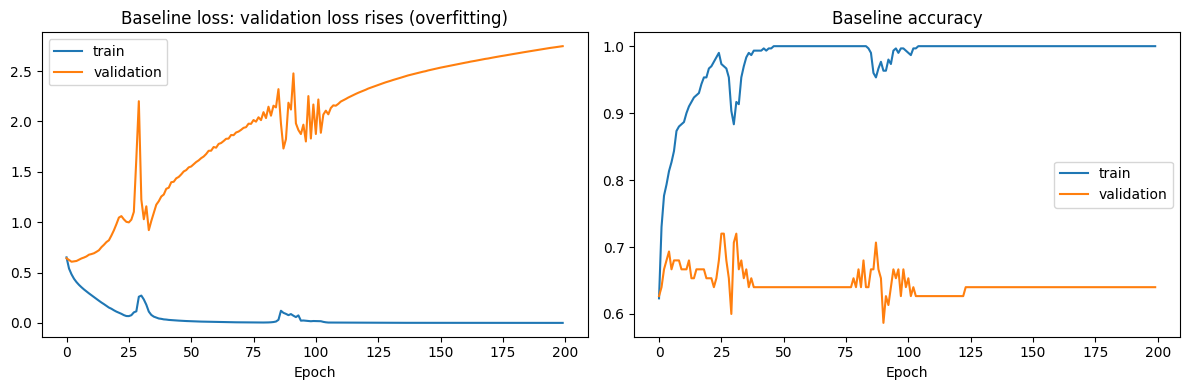

L2 (lambda=0.001)      train=0.936 test=0.792 gap=0.144
L2 (lambda=0.01)       train=0.923 test=0.832 gap=0.091
L2 (lambda=0.1)        train=0.507 test=0.504 gap=0.003
Dropout (0.2)          train=0.936 test=0.800 gap=0.136
Dropout (0.3)          train=0.925 test=0.768 gap=0.157
Dropout (0.5)          train=0.915 test=0.808 gap=0.107
Early stopping         train=0.781 test=0.760 gap=0.021

             Model  Epochs run  Train acc  Test acc  Train-Test gap
         Baseline         200      0.928     0.776           0.152
L2 (lambda=0.001)         200      0.936     0.792           0.144
 L2 (lambda=0.01)         200      0.923     0.832           0.091
  L2 (lambda=0.1)         200      0.507     0.504           0.003
    Dropout (0.2)         200      0.936     0.800           0.136
    Dropout (0.3)         200      0.925     0.768           0.157
    Dropout (0.5)         200      0.915     0.808           0.107
   Early stopping          18      0.781     0.760           0.021


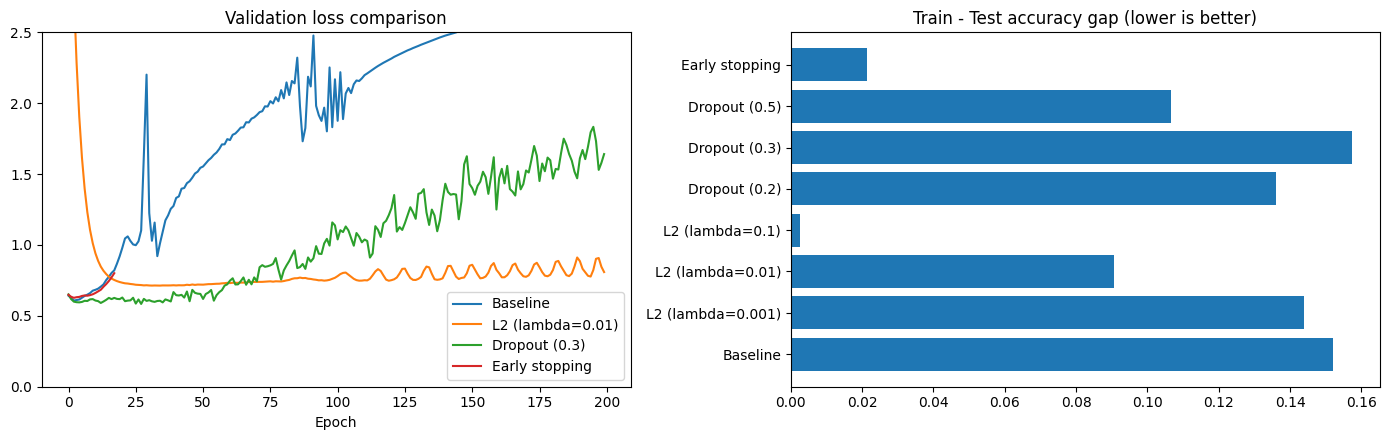

In [1]:
"""Experiment 10: L2, Dropout and Early Stopping Comparison"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42); tf.random.set_seed(42)

# ---------------- Small tabular dataset (~500 records, 8 clinical features) ----------------
X, y = make_classification(n_samples=500, n_features=8, n_informative=4, n_redundant=2,
                           flip_y=0.1, class_sep=0.8, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
sc = StandardScaler().fit(X_tr)
X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)
EPOCHS = 200

def build(l2=0.0, dropout=0.0):
    reg = regularizers.l2(l2) if l2 > 0 else None
    m = keras.Sequential([layers.Input((8,))])
    for units in [256, 256, 128]:                      # deliberately large
        m.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=keras.optimizers.Adam(0.001), loss="binary_crossentropy", metrics=["accuracy"])
    return m

results, histories = [], {}
def run(name, l2=0.0, dropout=0.0, early=False):
    m = build(l2, dropout)
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)] if early else []
    h = m.fit(X_tr, y_tr, validation_split=0.2, epochs=EPOCHS, batch_size=32, callbacks=cb, verbose=0)
    tr_acc = m.evaluate(X_tr, y_tr, verbose=0)[1]
    te_acc = m.evaluate(X_te, y_te, verbose=0)[1]
    results.append({"Model": name, "Epochs run": len(h.history["loss"]), "Train acc": tr_acc,
                    "Test acc": te_acc, "Train-Test gap": tr_acc - te_acc})
    histories[name] = h.history
    print(f"{name:22} train={tr_acc:.3f} test={te_acc:.3f} gap={tr_acc - te_acc:.3f}")

# ---------------- Task 1: baseline ----------------
run("Baseline")
h = histories["Baseline"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("Baseline loss: validation loss rises (overfitting)"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation")
ax[1].set_title("Baseline accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

# ---------------- Task 2: L2 ----------------
for lam in [0.001, 0.01, 0.1]:
    run(f"L2 (lambda={lam})", l2=lam)
# ---------------- Task 3: Dropout ----------------
for r in [0.2, 0.3, 0.5]:
    run(f"Dropout ({r})", dropout=r)
# ---------------- Task 4: Early stopping ----------------
run("Early stopping", early=True)

# ---------------- Task 5: table ----------------
table = pd.DataFrame(results)
print("\n", table.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name in ["Baseline", "L2 (lambda=0.01)", "Dropout (0.3)", "Early stopping"]:
    ax[0].plot(histories[name]["val_loss"], label=name)
ax[0].set_title("Validation loss comparison"); ax[0].set_xlabel("Epoch"); ax[0].set_ylim(0, 2.5); ax[0].legend()
ax[1].barh(table["Model"], table["Train-Test gap"]); ax[1].set_title("Train - Test accuracy gap (lower is better)")
plt.tight_layout(); plt.show()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4012s 24us/step
Train: (45000, 32, 32, 3) Val: (5000, 32, 32, 3) Test: (10000, 32, 32, 3)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,274 (2.26 MB)

 Trainable params: 591,274 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
704/704 - 21s - 29ms/step - accuracy: 0.3900 - loss: 1.6689 - val_accuracy: 0.5502 - val_loss: 1.2449
Epoch 2/10
704/704 - 5s - 7ms/step - accuracy: 0.5480 - loss: 1.2610 - val_accuracy: 0.6370 - val_loss: 1.0404
Epoch 3/10
704/704 - 5s - 7ms/step - accuracy: 0.6128 - loss: 1.0974 - val_accuracy: 0.6626 - val_loss: 0.9752
Epoch 4/10
704/704 - 5s - 7ms/step - accuracy: 0.6557 - loss: 0.9861 - val_accuracy: 0.6988 - val_loss: 0.8694
Epoch 5/10
704/704 - 5s - 7ms/step - accuracy: 0.6894 - loss: 0.8948 - val_accuracy: 0.7088 - val_loss: 0.8328
Epoch 6/10
704/704 - 5s - 7ms/step - accuracy: 0.7088 - loss: 0.8173 - val_accuracy: 0.7270 - val_loss: 0.7745
Epoch 7/10
704/704 - 5s - 7ms/step - accuracy: 0.7337 - loss: 0.7594 - val_accuracy: 0.7390 - val_loss: 0.7521
Epoch 8/10
704/704 - 5s - 7ms/step - accuracy: 0.7513 - loss: 0.7006 - val_accuracy: 0.7232 - val_loss: 0.8090
Epoch 9/10
704/704 - 5s - 7ms/step - accuracy: 0.7683 - loss: 0.6509 - val_accuracy: 0.7530 - val_loss: 0.7506

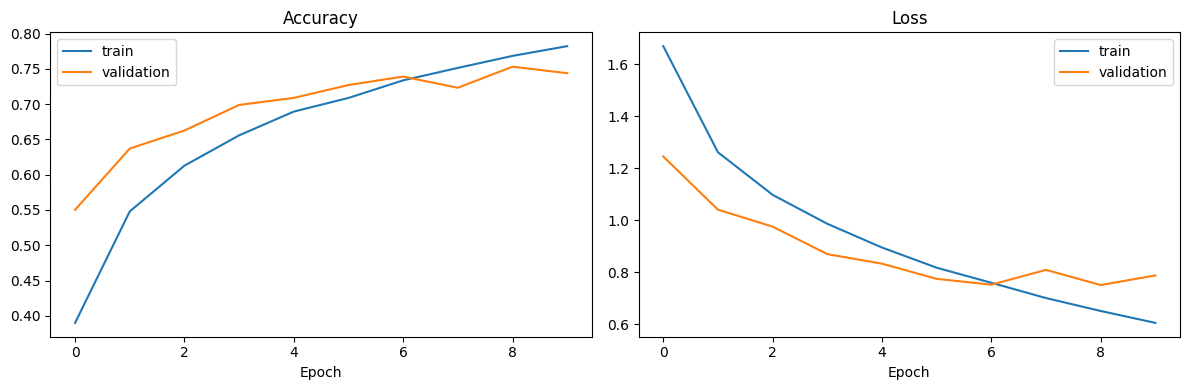

Test accuracy: 0.7263
              precision    recall  f1-score   support

    airplane       0.78      0.76      0.77      1000
  automobile       0.86      0.82      0.84      1000
        bird       0.78      0.47      0.58      1000
         cat       0.56      0.50      0.53      1000
        deer       0.67      0.68      0.68      1000
         dog       0.56      0.75      0.64      1000
        frog       0.84      0.71      0.77      1000
       horse       0.76      0.80      0.78      1000
        ship       0.82      0.87      0.85      1000
       truck       0.71      0.89      0.79      1000

    accuracy                           0.73     10000
   macro avg       0.73      0.73      0.72     10000
weighted avg       0.73      0.73      0.72     10000



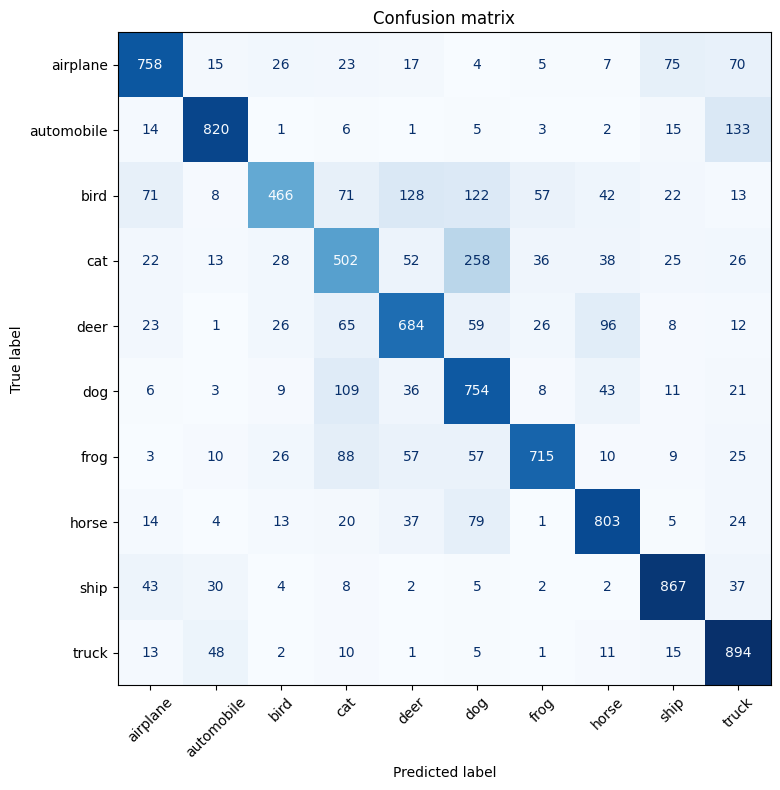

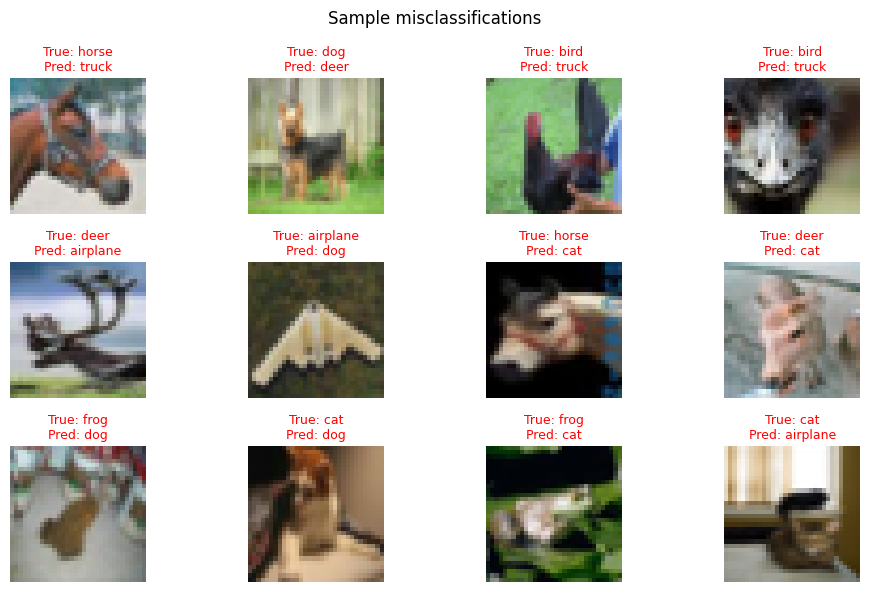

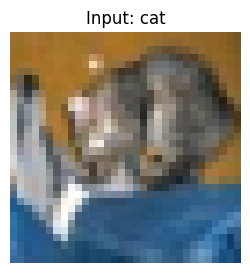

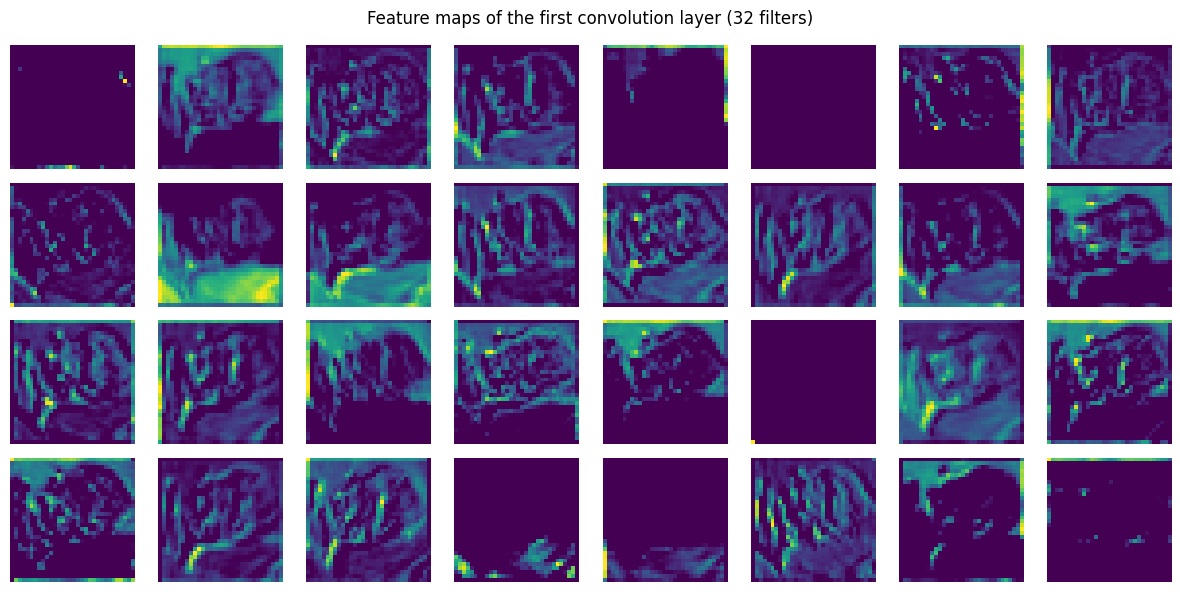

In [1]:

"""Experiment 11: CNN for Image Classification (CIFAR-10 used as the dataset)"""
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

np.random.seed(42); tf.random.set_seed(42)
USE_SYNTHETIC = False        # keep False; True only generates random images to smoke-test the code
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

# ---------------- Task 1: load, normalise, split ----------------
if USE_SYNTHETIC:
    x_all = np.random.randint(0, 256, (3000, 32, 32, 3), dtype=np.uint8); y_all = np.random.randint(0, 10, (3000, 1))
    x_test = np.random.randint(0, 256, (600, 32, 32, 3), dtype=np.uint8); y_test = np.random.randint(0, 10, (600, 1))
else:
    (x_all, y_all), (x_test, y_test) = keras.datasets.cifar10.load_data()

# For the garbage-classification folder dataset use this instead (images resized to 128x128):
# ds = keras.utils.image_dataset_from_directory("garbage_dataset/", image_size=(128, 128), batch_size=32)

x_all = x_all.astype("float32") / 255.0                    # normalise to 0-1
x_test = x_test.astype("float32") / 255.0
y_all, y_test = y_all.ravel(), y_test.ravel()
n_val = int(0.1 * len(x_all))
x_train, y_train = x_all[:-n_val], y_all[:-n_val]
x_val, y_val = x_all[-n_val:], y_all[-n_val:]
print("Train:", x_train.shape, "Val:", x_val.shape, "Test:", x_test.shape)

y_train_c = keras.utils.to_categorical(y_train, 10)
y_val_c = keras.utils.to_categorical(y_val, 10)
y_test_c = keras.utils.to_categorical(y_test, 10)

# ---------------- Task 2: build CNN ----------------
model = keras.Sequential([
    layers.Input((32, 32, 3)),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
model.summary()

# ---------------- Task 3: train with categorical cross-entropy ----------------
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
hist = model.fit(x_train, y_train_c, validation_data=(x_val, y_val_c), epochs=10, batch_size=64, verbose=2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.history["accuracy"], label="train"); ax[0].plot(hist.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist.history["loss"], label="train"); ax[1].plot(hist.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

test_loss, test_acc = model.evaluate(x_test, y_test_c, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

# ---------------- Task 4: confusion matrix & misclassifications ----------------
probs = model.predict(x_test, verbose=0)
y_pred = probs.argmax(axis=1)
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=range(10))
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion matrix"); plt.tight_layout(); plt.show()

wrong = np.where(y_pred != y_test)[0][:12]
plt.figure(figsize=(10, 6))
for i, idx in enumerate(wrong):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[idx]); plt.axis("off")
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=9, color="red")
plt.suptitle("Sample misclassifications"); plt.tight_layout(); plt.show()

# ---------------- Task 5: feature maps of first conv layer ----------------
fm_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
sample = x_test[0:1]
fmaps = fm_model.predict(sample, verbose=0)[0]            # (32, 32, 32)
plt.figure(figsize=(3, 3)); plt.imshow(sample[0]); plt.title(f"Input: {class_names[y_test[0]]}"); plt.axis("off"); plt.show()
plt.figure(figsize=(12, 6))
for i in range(32):
    plt.subplot(4, 8, i + 1); plt.imshow(fmaps[:, :, i], cmap="viridis"); plt.axis("off")
plt.suptitle("Feature maps of the first convolution layer (32 filters)"); plt.tight_layout(); plt.show()

Baseline           params= 282,250  time=  15.4s  test_acc=0.6191
3 conv layers      params= 225,034  time=  16.4s  test_acc=0.6245
4 conv layers      params= 454,666  time=  18.8s  test_acc=0.6137
5x5 filters        params= 316,554  time=  16.9s  test_acc=0.6105
16 base filters    params= 136,874  time=  14.7s  test_acc=0.5861
64 base filters    params= 600,650  time=  18.5s  test_acc=0.6368
Avg pooling        params= 282,250  time=  12.1s  test_acc=0.5774
Max pool + BN      params= 282,634  time=  16.9s  test_acc=0.5490
Avg pool + BN      params= 282,634  time=  14.3s  test_acc=0.6068
lr = 0.01          params= 282,250  time=  12.2s  test_acc=0.1000
lr = 0.0001        params= 282,250  time=  12.7s  test_acc=0.5174
batch = 32         params= 282,250  time=  19.8s  test_acc=0.6353
batch = 128        params= 282,250  time=  16.6s  test_acc=0.6119

   Configuration  Conv layers Kernel  Base filters Pooling    BN     LR  Batch  Params  Time (s)  Test accuracy
       Baseline            2 

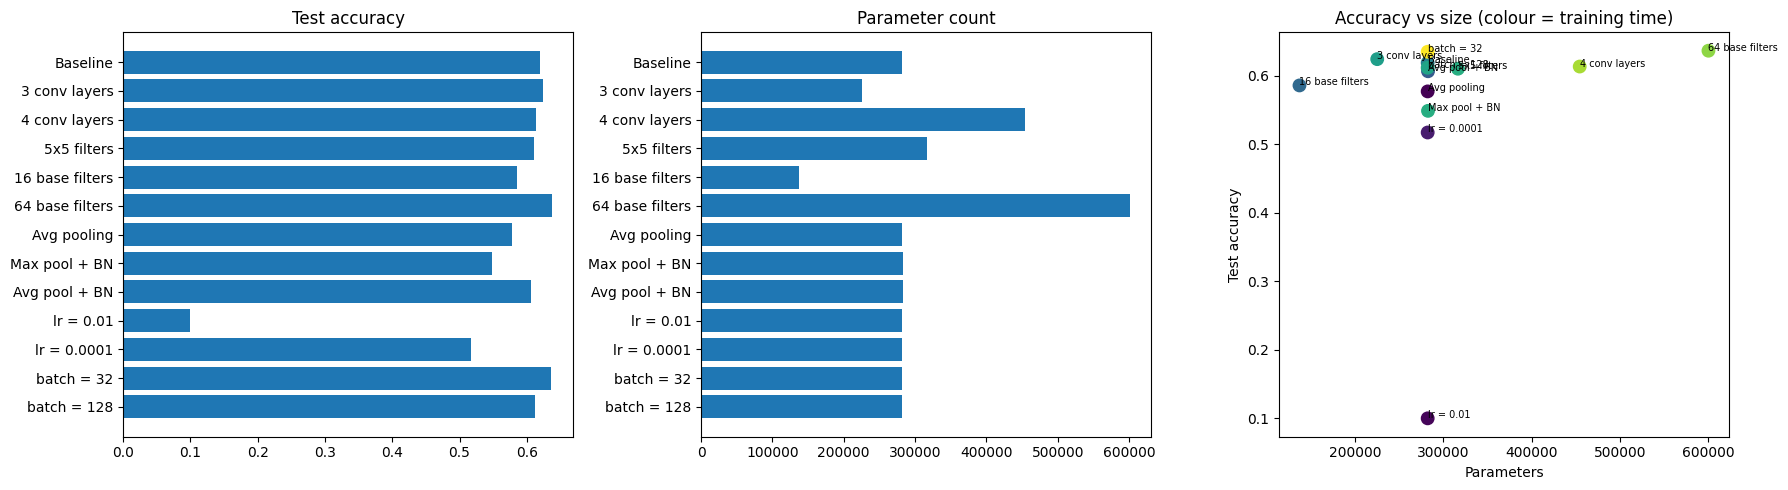

In [2]:
"""Experiment 12: CNN Architecture and Hyperparameter Comparison (CIFAR-10)"""
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42); tf.random.set_seed(42)
USE_SYNTHETIC = False        # keep False; True only generates random images to smoke-test the code
EPOCHS = 6                   # kept small so that all configurations finish quickly
N_TRAIN = 20000              # training subset size (reduce if your machine is slow)

# ---------------- Data ----------------
if USE_SYNTHETIC:
    x_train = np.random.rand(1500, 32, 32, 3).astype("float32"); y_train = np.random.randint(0, 10, 1500)
    x_test = np.random.rand(500, 32, 32, 3).astype("float32"); y_test = np.random.randint(0, 10, 500)
else:
    (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
    x_train = x_train[:N_TRAIN].astype("float32") / 255.0; y_train = y_train[:N_TRAIN].ravel()
    x_test = x_test.astype("float32") / 255.0; y_test = y_test.ravel()

# ---------------- Model builder ----------------
def build_cnn(n_conv=2, kernel=3, filters=32, pool="max", bn=False, lr=1e-3):
    m = keras.Sequential([layers.Input((32, 32, 3))])
    for i in range(n_conv):
        m.add(layers.Conv2D(filters * (2 ** i), kernel, padding="same"))
        if bn:
            m.add(layers.BatchNormalization())
        m.add(layers.Activation("relu"))
        m.add(layers.MaxPooling2D(2) if pool == "max" else layers.AveragePooling2D(2))
    m.add(layers.Flatten())
    m.add(layers.Dense(64, activation="relu"))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

BASE = dict(n_conv=2, kernel=3, filters=32, pool="max", bn=False, lr=1e-3, batch=64)

# One-factor-at-a-time experiments (Tasks 1-4)
experiments = [
    ("Baseline", {}),
    # Task 1: number of conv layers
    ("3 conv layers", dict(n_conv=3)), ("4 conv layers", dict(n_conv=4)),
    # Task 2: filter size and count
    ("5x5 filters", dict(kernel=5)), ("16 base filters", dict(filters=16)), ("64 base filters", dict(filters=64)),
    # Task 3: pooling and batch normalisation
    ("Avg pooling", dict(pool="avg")), ("Max pool + BN", dict(bn=True)), ("Avg pool + BN", dict(pool="avg", bn=True)),
    # Task 4: learning rate and batch size
    ("lr = 0.01", dict(lr=1e-2)), ("lr = 0.0001", dict(lr=1e-4)),
    ("batch = 32", dict(batch=32)), ("batch = 128", dict(batch=128)),
]

rows = []
for name, override in experiments:
    cfg = {**BASE, **override}
    batch = cfg.pop("batch")
    model = build_cnn(**cfg)
    t0 = time.time()
    model.fit(x_train, y_train, epochs=EPOCHS, batch_size=batch, validation_split=0.1, verbose=0)
    train_time = time.time() - t0
    test_acc = model.evaluate(x_test, y_test, verbose=0)[1]
    rows.append({"Configuration": name, "Conv layers": cfg["n_conv"], "Kernel": f"{cfg['kernel']}x{cfg['kernel']}",
                 "Base filters": cfg["filters"], "Pooling": cfg["pool"], "BN": cfg["bn"], "LR": cfg["lr"],
                 "Batch": batch, "Params": model.count_params(), "Time (s)": round(train_time, 1),
                 "Test accuracy": round(test_acc, 4)})
    print(f"{name:18} params={model.count_params():>8,}  time={train_time:6.1f}s  test_acc={test_acc:.4f}")

# ---------------- Task 5: results table ----------------
df = pd.DataFrame(rows)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)
print("\n", df.to_string(index=False))
df.to_csv("cnn_comparison_results.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].barh(df["Configuration"], df["Test accuracy"]); ax[0].set_title("Test accuracy"); ax[0].invert_yaxis()
ax[1].barh(df["Configuration"], df["Params"]); ax[1].set_title("Parameter count"); ax[1].invert_yaxis()
ax[2].scatter(df["Params"], df["Test accuracy"], c=df["Time (s)"], cmap="viridis", s=80)
for _, r in df.iterrows():
    ax[2].annotate(r["Configuration"], (r["Params"], r["Test accuracy"]), fontsize=7)
ax[2].set_xlabel("Parameters"); ax[2].set_ylabel("Test accuracy"); ax[2].set_title("Accuracy vs size (colour = training time)")
plt.tight_layout(); plt.show()